In [1]:
import duckdb
import graphviz
import re
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from graphviz import Digraph
import seaborn as sns
import pyarrow
import jupyter
import openpyxl
import textwrap
import os
import requests
from urllib.request import Request, urlopen
import shutil
from IPython.display import display
from pathlib import Path

In [2]:
OUTPUT_DIR = Path.cwd() / "outputs" / "figures"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Output directory:", OUTPUT_DIR.resolve())
print("Directory exists:", OUTPUT_DIR.exists())

Output directory: C:\Users\Medam Hexnebyek\Desktop\AnalysisAndVisualizationOfSocialMediaData\outputs\figures
Directory exists: True


In [3]:
FILE_PATH = 'data/raw/data/programming-00000-of-00007-682384b233d9a62b.parquet'
query = f"""
    SELECT *
    FROM '{FILE_PATH}'
    LIMIT 5
"""
df_preview = duckdb.sql(query).df()
display(df_preview)

,archived,author,author_fullname,body,comment_type,controversiality,created_utc,edited,gilded,id,...,locked,name,parent_id,permalink,retrieved_on,score,subreddit_id,subreddit_name_prefixed,subreddit_type,total_awards_received
0,False,[deleted],None,[deleted],None,0,1543622641,False,0,eatmcpf,...,None,None,t1_easikql,/r/programming/comments/a1rp4s/why_is_2_i_i_fa...,1546258391,31,t5_2fwo,r/programming,public,None
1,False,13steinj,t2_i487l,When most people say what he did they are refe...,None,0,1544758550,False,0,ebqu3hi,...,None,None,t1_ebqm24t,/r/programming/comments/a5gx0c/how_reddit_rank...,1547582038,1,t5_2fwo,r/programming,public,None
2,False,noir_lord,t2_3655m,"To err is human, to really fuck up you need a ...",None,0,1543622647,False,0,eatmcxp,...,None,None,t1_eatkolb,/r/programming/comments/a1t38z/a_collection_of...,1546258394,2,t5_2fwo,r/programming,public,None
3,False,ArrrGaming,t2_c3hig,Why would I need to search the menu for my fav...,None,0,1544758569,False,0,ebqu4ca,...,None,None,t3_a5sg9k,/r/programming/comments/a5sg9k/how_unix_progra...,1547582048,1,t5_2fwo,r/programming,public,None
4,False,stevegrossman83b,t2_1lm5r842,You can always calculate and cache the inverse...,None,0,1543622776,False,0,eatmhv4,...,None,None,t1_eatfge5,/r/programming/comments/a1sbwp/not_all_cpu_ope...,1546258455,2,t5_2fwo,r/programming,public,None


In [4]:
query = f"""
    SELECT id, parent_id, link_id
    FROM '{FILE_PATH}'
    WHERE parent_id IS NOT NULL
    LIMIT 5
"""
format_check = duckdb.sql(query).df()
display(format_check)

,id,parent_id,link_id
0,eatmcpf,t1_easikql,t3_a1rp4s
1,ebqu3hi,t1_ebqm24t,t3_a5gx0c
2,eatmcxp,t1_eatkolb,t3_a1t38z
3,ebqu4ca,t3_a5sg9k,t3_a5sg9k
4,eatmhv4,t1_eatfge5,t3_a1sbwp


In [5]:
print(f"---Dataframe Shape---")
print(f"Rows: {df_preview.shape[0]}, Columns: {df_preview.shape[1]}\n")
print(f"---Column Names and Data Types---")
print(f"{df_preview.dtypes}\n")
print(f"---Total Dataset---")
total_rows = duckdb.sql(f"SELECT COUNT(*) FROM '{FILE_PATH}'").fetchone()[0]
print(f"Full Parquet file contains: {total_rows:,} rows.\n")

---Dataframe Shape---
Rows: 5, Columns: 21

---Column Names and Data Types---
archived                      str
author                        str
author_fullname               str
body                          str
comment_type               object
controversiality              str
created_utc                   str
edited                        str
gilded                        str
id                            str
link_id                       str
locked                     object
name                       object
parent_id                     str
permalink                     str
retrieved_on                  str
score                         str
subreddit_id                  str
subreddit_name_prefixed       str
subreddit_type                str
total_awards_received      object
dtype: object

---Total Dataset---
Full Parquet file contains: 1,071,907 rows.



In [6]:
id_check = duckdb.sql(f"""
    SELECT id, parent_id, link_id, author
    FROM '{FILE_PATH}'
    WHERE parent_id IS NOT NULL AND parent_id != 'None'
    LIMIT 10
""").df()
display(id_check)
post_query = f"""
    SELECT
        link_id,
        COUNT(*) AS num_comments
    FROM '{FILE_PATH}'
    WHERE body IS NOT NULL
        AND author != '[deleted]'
    GROUP BY link_id
    HAVING COUNT(*) BETWEEN 20 AND 40
    LIMIT 5
"""
post_candidates = duckdb.sql(post_query).df()
display(post_candidates)

,id,parent_id,link_id,author
0,eatmcpf,t1_easikql,t3_a1rp4s,[deleted]
1,ebqu3hi,t1_ebqm24t,t3_a5gx0c,13steinj
2,eatmcxp,t1_eatkolb,t3_a1t38z,noir_lord
3,ebqu4ca,t3_a5sg9k,t3_a5sg9k,ArrrGaming
4,eatmhv4,t1_eatfge5,t3_a1sbwp,stevegrossman83b
5,ebqu9pz,t1_ebph33i,t3_a5mk9z,iBzOtaku
6,eatmk3e,t3_a1xjwr,t3_a1xjwr,claytonkb
7,ebqujy2,t1_ebq2sv5,t3_a5sg9k,clefairy
8,eatmtnb,t3_a1gxu3,t3_a1gxu3,BunnyBlue896
9,ebquku8,t1_ebqt7s7,t3_a5y50c,sastraxi


,link_id,num_comments
0,t3_a5qm02,39
1,t3_a219ba,22
2,t3_68fm5w,30
3,t3_683939,34
4,t3_68g9cy,25


In [7]:
selected_post = 't3_63bxdl'
thread_query = f"""
    SELECT
        id,
        parent_id,
        link_id,
        author,
        body
    FROM '{FILE_PATH}'
    WHERE link_id = '{selected_post}'
    ORDER BY created_utc
"""
thread_df = duckdb.sql(thread_query).df()
print(f"Number of comments: ", len(thread_df))
display(thread_df)

Number of comments:  22


,id,parent_id,link_id,author,body
0,dftbll2,t3_63bxdl,t3_63bxdl,[deleted],[deleted]
1,dftchpw,t3_63bxdl,t3_63bxdl,mattwarren,There's also a bit more info in the related Gi...
2,dfteepk,t3_63bxdl,t3_63bxdl,TheHillwoodMonkey,The orginal Java proposal is [here](http://ope...
3,dftocdc,t1_dfteepk,t3_63bxdl,jackmott2,&gt; A truly blessed language would not consum...
4,dftqm4h,t1_dfteepk,t3_63bxdl,mirhagk,They are obviously taking the point to the ext...
5,dfty0af,t1_dfteepk,t3_63bxdl,tragicshark,&gt; A truly blessed language would not consum...
6,dftzv08,t1_dfteepk,t3_63bxdl,cat_in_the_wall,C++ generates garbage. The heap is garbage wai...
7,dfu0h92,t1_dftzv08,t3_63bxdl,TheHillwoodMonkey,"Or Forth, I suppose"
8,dfu5unv,t1_dftzv08,t3_63bxdl,flukus,I don't know if manually is the right word eit...
9,dfu673i,t1_dfu0h92,t3_63bxdl,ummwut,Forth is pretty divine... if you construct it ...


In [8]:
TARGET_POST = 't3_63bxdl'
tree_query = f"""
    WITH RECURSIVE tree AS (
        SELECT
            id,
            parent_id,
            body,
            author,
            1 AS depth
        FROM read_parquet('{FILE_PATH}')
        WHERE link_id = '{TARGET_POST}'
          AND parent_id = '{TARGET_POST}'
        UNION ALL
        SELECT
            c.id,
            c.parent_id,
            c.body,
            c.author,
            t.depth + 1 AS depth
        FROM read_parquet('{FILE_PATH}') AS c
        INNER JOIN tree AS t
            ON c.parent_id = 't1_' || t.id
        WHERE c.link_id = '{TARGET_POST}'
    )
    SELECT *
    FROM tree
    ORDER BY depth, id;
"""
df_tree = duckdb.sql(tree_query).df()
print(f"Successfully extracted a tree with {len(df_tree)} comments!")
display(df_tree[['depth', 'id', 'parent_id', 'author']].head(15))
print("Comments by depth")
display(
    df_tree.groupby('depth')
    .size()
    .reset_index(name="comment_count")
)

Successfully extracted a tree with 22 comments!


,depth,id,parent_id,author
0,1,dftbll2,t3_63bxdl,[deleted]
1,1,dftchpw,t3_63bxdl,mattwarren
2,1,dfteepk,t3_63bxdl,TheHillwoodMonkey
3,1,dfu81dd,t3_63bxdl,TinynDP
4,2,dftocdc,t1_dfteepk,jackmott2
5,2,dftqm4h,t1_dfteepk,mirhagk
6,2,dfty0af,t1_dfteepk,tragicshark
7,2,dftzv08,t1_dfteepk,cat_in_the_wall
8,3,dfu0h92,t1_dftzv08,TheHillwoodMonkey
9,3,dfu5unv,t1_dftzv08,flukus


Comments by depth


,depth,comment_count
0,1,4
1,2,4
2,3,3
3,4,4
4,5,4
5,6,2
6,7,1


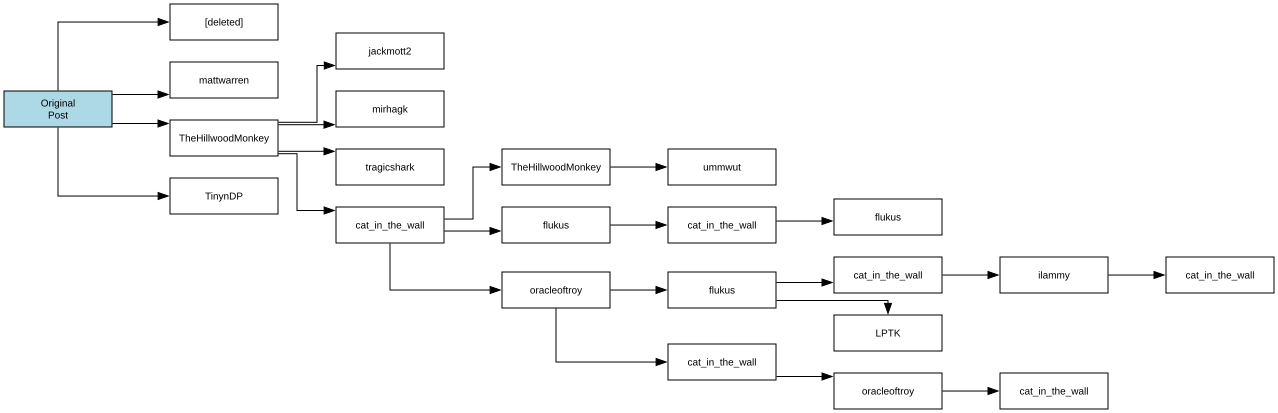

In [9]:
dot = graphviz.Digraph(format="svg")
dot.attr(rankdir="LR")
dot.attr(splines="ortho")
dot.attr(
    "node",
    shape="box",
    style="solid",
    fillcolor="white",
    fontname="Arial",
    fontsize="10",
    width="1.5",
    height="0.5"
)
dot.attr(nodesep="0.3", ranksep="0.8")
dot.node(
    TARGET_POST,
    "Original\nPost",
    style="filled",
    fillcolor="lightblue",
    tooltip="Original Reddit post"
)
for _, row in df_tree.iterrows():
    comment_id = str(row["id"])
    parent_id = str(row["parent_id"])
    clean_parent_id = parent_id.replace("t1_", "")
    author = str(row["author"])
    body = str(row["body"])
    body_preview = re.sub(r"\s+", " ", body).strip()
    if len(body_preview) > 300:
        body_preview = body_preview[:300] + "..."
    tooltip_text = f"Author: {author}\nComment: {body_preview}"
    dot.node(
        comment_id,
        label=author,
        tooltip=tooltip_text
    )
    dot.edge(clean_parent_id, comment_id)
display(dot)

In [10]:
tree_path = OUTPUT_DIR / "comment_tree"
saved_tree = dot.render(
    filename=str(tree_path),
    format="png",
    cleanup=True
)
print("Saved tree:", saved_tree)
print("File exists:", Path(saved_tree).exists())

Saved tree: C:\Users\Medam Hexnebyek\Desktop\AnalysisAndVisualizationOfSocialMediaData\outputs\figures\comment_tree.png
File exists: True


In [11]:
quality_query = f"""
SELECT
    COUNT(*) AS total_rows,
    COUNT(DISTINCT id) AS unique_comment_ids,
    COUNT(*) FILTER (WHERE body IS NULL) AS missing_bodies,
    COUNT(*) FILTER (WHERE author IS NULL) AS missing_authors,
    COUNT(*) FILTER (WHERE author = '[deleted]') AS deleted_authors,
    COUNT(*) FILTER (WHERE parent_id IS NULL) AS missing_parent_ids,
    COUNT(*) FILTER (WHERE link_id IS NULL) AS missing_post_ids
FROM read_parquet('{FILE_PATH}')
"""
quality_df = duckdb.sql(quality_query).df()
display(quality_df)

,total_rows,unique_comment_ids,missing_bodies,missing_authors,deleted_authors,missing_parent_ids,missing_post_ids
0,1071907,1070377,0,0,127743,0,0


In [12]:
duplicate_query = f"""
SELECT
    COUNT(*) AS rows_with_repeated_ids,
    COUNT(DISTINCT id) AS repeated_id_count,
    MAX(id_count) AS highest_occurrences
FROM (
    SELECT id, COUNT(*) AS id_count
    FROM read_parquet('{FILE_PATH}')
    GROUP BY id
    HAVING COUNT(*) > 1
)
JOIN read_parquet('{FILE_PATH}') USING (id)
"""
display(duckdb.sql(duplicate_query).df())

,rows_with_repeated_ids,repeated_id_count,highest_occurrences
0,3038,1508,3


In [13]:
hierarchy_query = f"""
SELECT
    CASE
        WHEN starts_with(parent_id, 't1_')
            THEN 'Reply to comment'
        WHEN starts_with(parent_id, 't3_')
            THEN 'Top-level comment'
        ELSE 'Other / Unknown'
    END AS comment_level,
    COUNT(*) AS comment_count,
    ROUND(
        COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (),
        2
    ) AS percentage
FROM read_parquet('{FILE_PATH}')
GROUP BY comment_level
ORDER BY comment_count DESC;
"""

hierarchy_df = duckdb.sql(hierarchy_query).df()
display(hierarchy_df)

,comment_level,comment_count,percentage
0,Reply to comment,847486,79.06
1,Top-level comment,224421,20.94


Saved: C:\Users\Medam Hexnebyek\Desktop\AnalysisAndVisualizationOfSocialMediaData\outputs\figures\comment_hierarchy.png
File exists: True


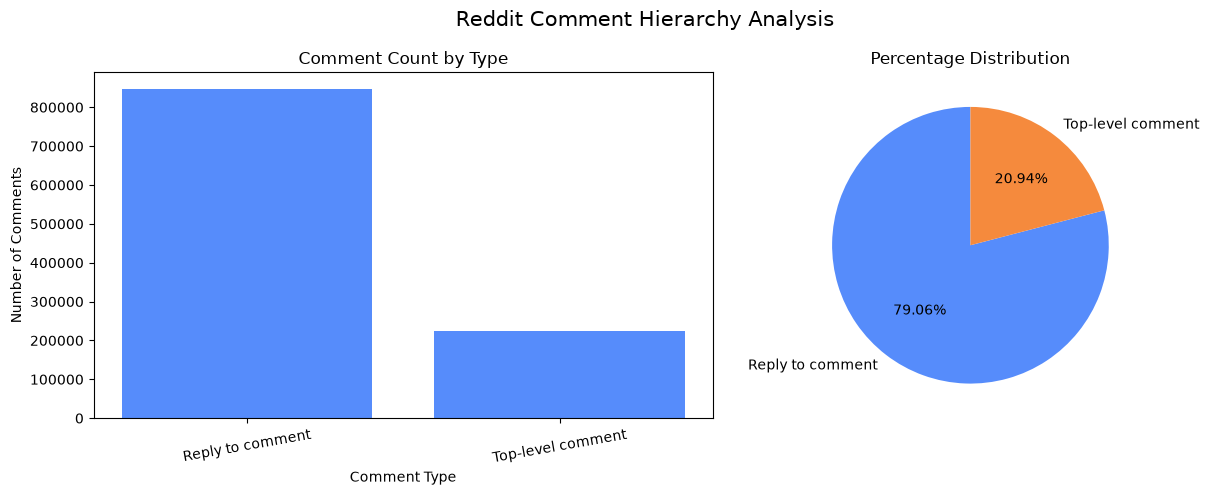

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].bar(
    hierarchy_df["comment_level"],
    hierarchy_df["comment_count"]
)
axes[0].set_title("Comment Count by Type")
axes[0].set_xlabel("Comment Type")
axes[0].set_ylabel("Number of Comments")
axes[0].ticklabel_format(style="plain", axis="y")
axes[0].tick_params(axis="x", rotation=10)
axes[1].pie(
    hierarchy_df["comment_count"],
    labels=hierarchy_df["comment_level"],
    autopct="%1.2f%%",
    startangle=90
)
axes[1].set_title("Percentage Distribution")
fig.suptitle("Reddit Comment Hierarchy Analysis", fontsize=15)
plt.tight_layout()
fig.tight_layout()
save_path = OUTPUT_DIR / "comment_hierarchy.png"
fig.savefig(save_path, dpi=300, bbox_inches="tight")
print("Saved:", save_path.resolve())
print("File exists:", save_path.exists())
plt.show()